<a href="https://colab.research.google.com/github/sanyasana1/MN/blob/main/%D0%9B%D0%A0_8_%D0%9B%D0%B0%D0%B7%D0%B0%D1%80%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)

display(iris_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

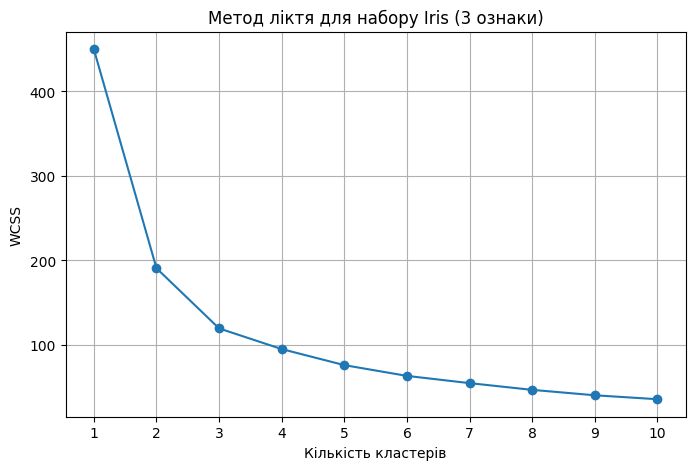

In [3]:
iris_features = iris_df.iloc[:, :3]
iris_scaler = StandardScaler()
iris_scaled = iris_scaler.fit_transform(iris_features)

iris_wcss = []
iris_k_values = range(1, 11)

for k in iris_k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(iris_scaled)
    iris_wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(iris_k_values, iris_wcss, marker="o")
plt.title("Метод ліктя для набору Iris (3 ознаки)")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(list(iris_k_values))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

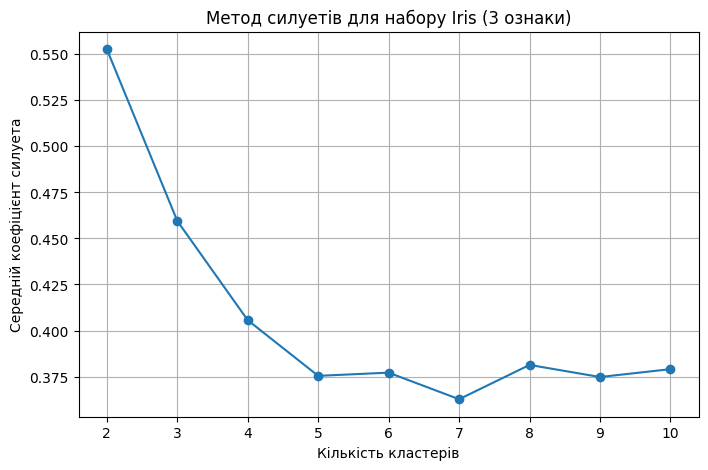

Найкраща кількість кластерів за силуетом: 2


In [4]:
iris_silhouette = []
iris_silhouette_k = range(2, 11)

for k in iris_silhouette_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(iris_scaled)
    iris_silhouette.append(silhouette_score(iris_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(iris_silhouette_k, iris_silhouette, marker="o")
plt.title("Метод силуетів для набору Iris (3 ознаки)")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(iris_silhouette_k))
plt.grid(True)
plt.show()

print("Найкраща кількість кластерів за силуетом:",
      list(iris_silhouette_k)[int(pd.Series(iris_silhouette).idxmax())])

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

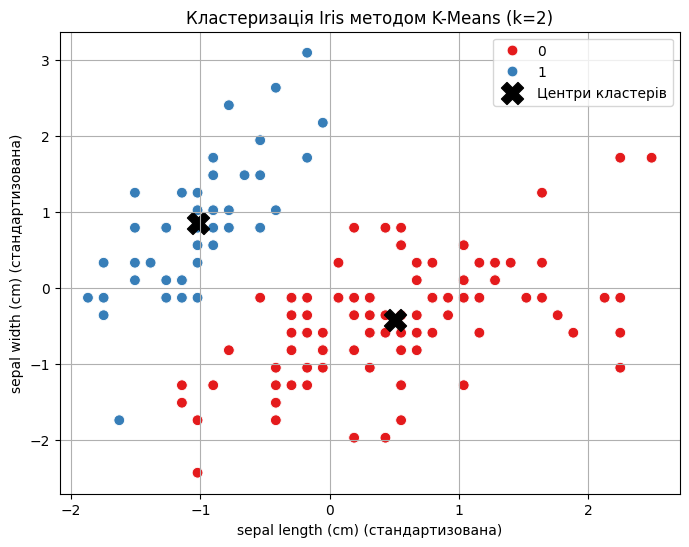

Координати центрів у просторі перших двох ознак:
[[ 0.50728948 -0.42663134]
 [-1.01457897  0.85326268]]


In [5]:
iris_final_model = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_final_labels = iris_final_model.fit_predict(iris_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=iris_scaled[:, 0],
    y=iris_scaled[:, 1],
    hue=iris_final_labels,
    palette="Set1",
    s=60
)
centers_2d = iris_final_model.cluster_centers_[:, :2]
plt.scatter(
    centers_2d[:, 0], centers_2d[:, 1],
    marker="X", s=250, c="black", label="Центри кластерів"
)
plt.title("Кластеризація Iris методом K-Means (k=2)")
plt.xlabel(iris_features.columns[0] + " (стандартизована)")
plt.ylabel(iris_features.columns[1] + " (стандартизована)")
plt.legend()
plt.grid(True)
plt.show()

print("Координати центрів у просторі перших двох ознак:")
print(centers_2d)

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print(df.isnull().sum())
print("\nЗагальна кількість пропущених значень:", int(df.isnull().sum().sum()))

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Загальна кількість пропущених значень: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Кількість дублікатів:", int(df.duplicated().sum()))

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
target_column = "GradeClass"
X = df.drop(columns=[target_column, "StudentID"])
y = df[target_column]

X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

classification_scaler = StandardScaler()
X_train_scaled = classification_scaler.fit_transform(X_train)
X_test_scaled = classification_scaler.transform(X_test)

print("Розмір навчальної вибірки:", X_train_scaled.shape)
print("Розмір тестової вибірки:", X_test_scaled.shape)
print("Кількість класів:", y.nunique())

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)
Кількість класів: 5


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_parameters,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train_scaled, y_train)

rf_best_model = rf_grid.best_estimator_
rf_predictions = rf_best_model.predict(X_test_scaled)
rf_cv_accuracy = rf_grid.best_score_
rf_test_accuracy = accuracy_score(y_test, rf_predictions)

print("Найкращі параметри Random Forest:", rf_grid.best_params_)
print(f"Середня CV-точність: {rf_cv_accuracy:.4f}")
print(f"Тестова accuracy: {rf_test_accuracy:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
lr_parameters = {
    "C": [0.1, 1, 10],
    "penalty": ["l1", "l2"],
    "solver": ["saga"],
    "max_iter": [5000]
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=lr_parameters,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
lr_grid.fit(X_train_scaled, y_train)

lr_best_model = lr_grid.best_estimator_
lr_predictions = lr_best_model.predict(X_test_scaled)
lr_cv_accuracy = lr_grid.best_score_
lr_test_accuracy = accuracy_score(y_test, lr_predictions)

print("Найкращі параметри Logistic Regression:", lr_grid.best_params_)
print(f"Середня CV-точність: {lr_cv_accuracy:.4f}")
print(f"Тестова accuracy: {lr_test_accuracy:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Найкращі параметри Logistic Regression: {'C': 0.1, 'max_iter': 5000, 'penalty': 'l1', 'solver': 'saga'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
svm_parameters = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    SVC(),
    param_grid=svm_parameters,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)
svm_grid.fit(X_train_scaled, y_train)

svm_best_model = svm_grid.best_estimator_
svm_predictions = svm_best_model.predict(X_test_scaled)
svm_cv_accuracy = svm_grid.best_score_
svm_test_accuracy = accuracy_score(y_test, svm_predictions)

print("Найкращі параметри SVM:", svm_grid.best_params_)
print(f"Середня CV-точність: {svm_cv_accuracy:.4f}")
print(f"Тестова accuracy: {svm_test_accuracy:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
classification_results = pd.DataFrame({
    "Модель": ["Random Forest", "Logistic Regression", "SVM"],
    "CV accuracy": [rf_cv_accuracy, lr_cv_accuracy, svm_cv_accuracy],
    "Test accuracy": [rf_test_accuracy, lr_test_accuracy, svm_test_accuracy]
}).sort_values("CV accuracy", ascending=False).reset_index(drop=True)

display(classification_results)

best_model_name = classification_results.loc[0, "Модель"]
best_model = {
    "Random Forest": rf_best_model,
    "Logistic Regression": lr_best_model,
    "SVM": svm_best_model
}[best_model_name]

best_predictions = best_model.predict(X_test_scaled)
print("Найкраща модель за середньою CV-точністю:", best_model_name)
print("\nЗвіт класифікації для найкращої моделі:")
print(classification_report(y_test, best_predictions, zero_division=0))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.921071,0.910230
1,SVM,0.852065,0.858038
2,Logistic Regression,0.802411,0.818372


Найкраща модель за середньою CV-точністю: Random Forest

Звіт класифікації для найкращої моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

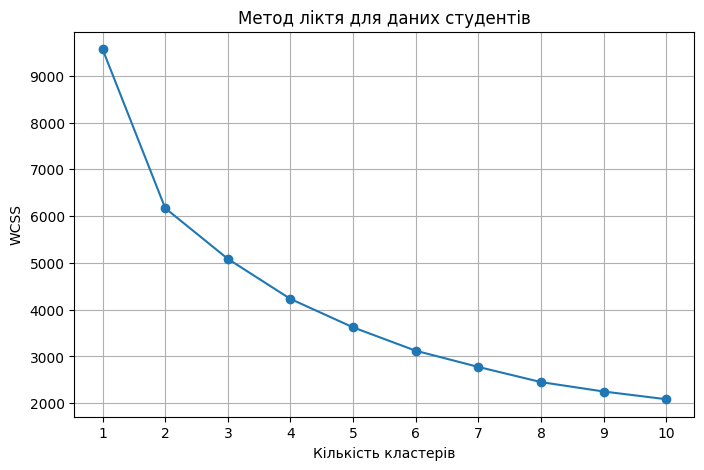

In [20]:
student_cluster_columns = ["Age", "StudyTimeWeekly", "Absences", "GPA"]
student_cluster_data = df[student_cluster_columns].copy()

student_cluster_data = student_cluster_data.apply(pd.to_numeric, errors="coerce")
student_cluster_data = student_cluster_data.fillna(student_cluster_data.median())

student_scaler = StandardScaler()
student_cluster_scaled = student_scaler.fit_transform(student_cluster_data)

student_wcss = []
student_k_values = range(1, 11)

for k in student_k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(student_cluster_scaled)
    student_wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(student_k_values, student_wcss, marker="o")
plt.title("Метод ліктя для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(list(student_k_values))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

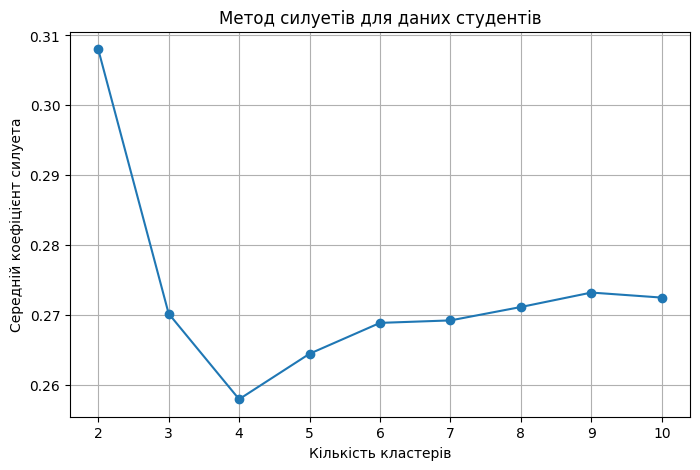

Найкраща кількість кластерів за силуетом: 2


In [21]:
student_silhouette = []
student_silhouette_k = range(2, 11)

for k in student_silhouette_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(student_cluster_scaled)
    student_silhouette.append(silhouette_score(student_cluster_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(student_silhouette_k, student_silhouette, marker="o")
plt.title("Метод силуетів для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(list(student_silhouette_k))
plt.grid(True)
plt.show()

print("Найкраща кількість кластерів за силуетом:",
      list(student_silhouette_k)[int(pd.Series(student_silhouette).idxmax())])

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [22]:
%pip -q install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [23]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [24]:
pca_features = df.drop(columns=["StudentID", "GradeClass"])
pca_features = pd.get_dummies(pca_features, drop_first=False)
pca_features = pca_features.apply(pd.to_numeric, errors="coerce")
pca_features = pca_features.fillna(pca_features.median())

print("Розмір набору ознак для PCA:", pca_features.shape)

Розмір набору ознак для PCA: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [25]:
pca_scaler = StandardScaler()
pca_scaled = pca_scaler.fit_transform(pca_features)

pca_model = PCA()
pca_transformed_all = pca_model.fit_transform(pca_scaled)
explained_variance = pca_model.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")
for component_number, variance in enumerate(explained_variance, start=1):
    print(f"Компонента {component_number}: {variance:.4f} ({variance * 100:.2f}%)")

Частка поясненої дисперсії кожної компоненти:
Компонента 1: 0.1525 (15.25%)
Компонента 2: 0.0861 (8.61%)
Компонента 3: 0.0827 (8.27%)
Компонента 4: 0.0807 (8.07%)
Компонента 5: 0.0786 (7.86%)
Компонента 6: 0.0779 (7.79%)
Компонента 7: 0.0763 (7.63%)
Компонента 8: 0.0760 (7.60%)
Компонента 9: 0.0744 (7.44%)
Компонента 10: 0.0738 (7.38%)
Компонента 11: 0.0717 (7.17%)
Компонента 12: 0.0675 (6.75%)
Компонента 13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

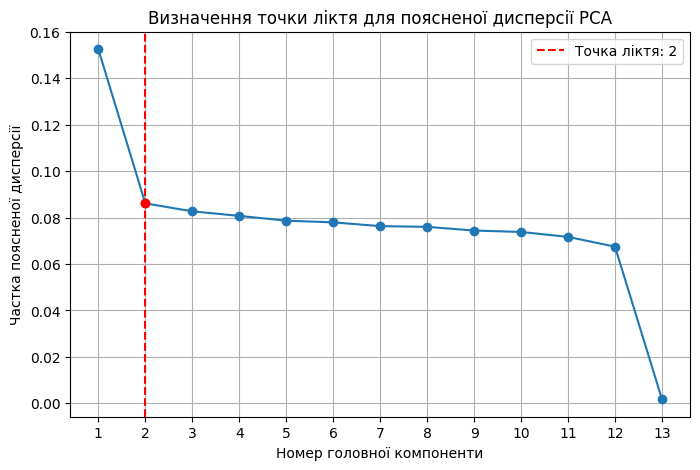

Кількість компонент за KneeLocator: 2


In [26]:
component_numbers = np.arange(1, len(explained_variance) + 1)

knee_locator = KneeLocator(
    component_numbers,
    explained_variance,
    curve="convex",
    direction="decreasing"
)
n_components_knee = knee_locator.knee

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, explained_variance, marker="o")
if n_components_knee is not None:
    plt.axvline(n_components_knee, color="red", linestyle="--",
                label=f"Точка ліктя: {n_components_knee}")
    plt.scatter(
        n_components_knee,
        explained_variance[n_components_knee - 1],
        color="red", zorder=3
    )
    plt.legend()
plt.title("Визначення точки ліктя для поясненої дисперсії PCA")
plt.xlabel("Номер головної компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(component_numbers)
plt.grid(True)
plt.show()

if n_components_knee is None:
    # Резервний варіант
    n_components_knee = int(np.argmax(np.diff(explained_variance)) + 2)
    n_components_knee = max(1, min(n_components_knee, len(explained_variance)))

print("Кількість компонент за KneeLocator:", n_components_knee)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

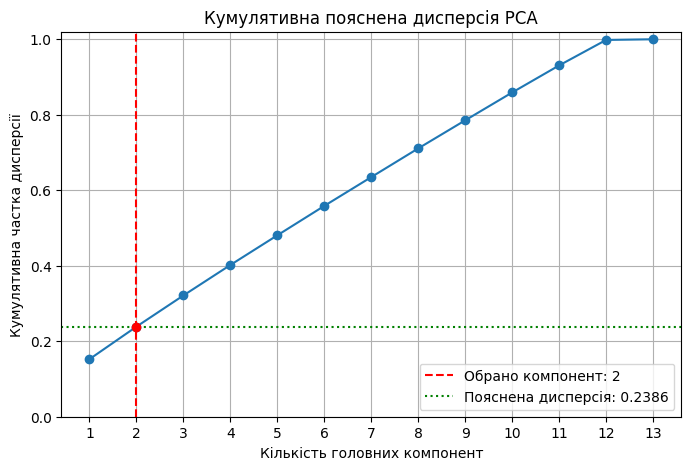

Обрано головних компонент: 2
Кумулятивна частка поясненої дисперсії: 0.2386 (23.86%)
Розмір даних після PCA: (2392, 2)


In [27]:
cumulative_variance = np.cumsum(explained_variance)
component_axis = np.arange(1, len(cumulative_variance) + 1)

selected_variance = cumulative_variance[n_components_knee - 1]

plt.figure(figsize=(8, 5))
plt.plot(component_axis, cumulative_variance, marker="o")
plt.axvline(n_components_knee, color="red", linestyle="--",
            label=f"Обрано компонент: {n_components_knee}")
plt.axhline(selected_variance, color="green", linestyle=":",
            label=f"Пояснена дисперсія: {selected_variance:.4f}")
plt.scatter(n_components_knee, selected_variance, color="red", zorder=3)
plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(component_axis)
plt.ylim(0, 1.02)
plt.grid(True)
plt.legend()
plt.show()

print(f"Обрано головних компонент: {n_components_knee}")
print(f"Кумулятивна частка поясненої дисперсії: {selected_variance:.4f} "
      f"({selected_variance * 100:.2f}%)")

pca_selected = pca_transformed_all[:, :n_components_knee]
print("Розмір даних після PCA:", pca_selected.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [28]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

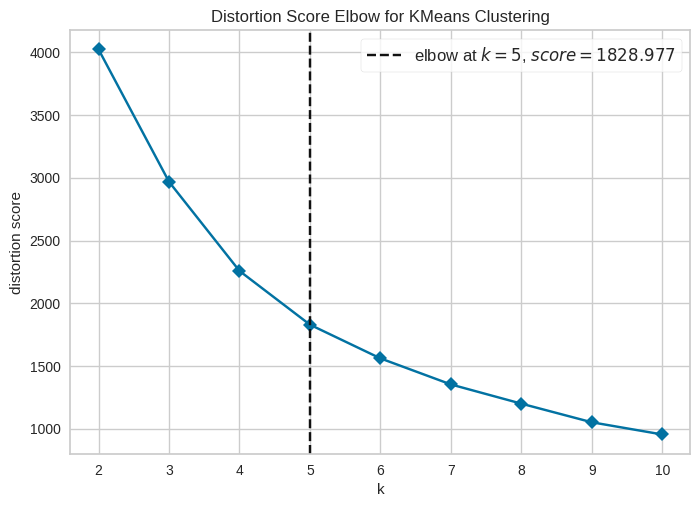

Оптимальна кількість кластерів за KElbowVisualizer: 5

ПІДСУМОК
Iris: найкращий силует для k = 2
Студенти: найкращий силует для k = 2
PCA: компонент = 2 ; пояснена частка дисперсії = 0.2386


In [29]:
pca_kmeans = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(
    pca_kmeans,
    k=(2, 11),
    metric="distortion",
    timings=False
)
elbow_visualizer.fit(pca_selected)
elbow_visualizer.show()

print("Оптимальна кількість кластерів за KElbowVisualizer:",
      elbow_visualizer.elbow_value_)

print("\nПІДСУМОК")
print("Iris: найкращий силует для k =",
      list(iris_silhouette_k)[int(pd.Series(iris_silhouette).idxmax())])
print("Студенти: найкращий силует для k =",
      list(student_silhouette_k)[int(pd.Series(student_silhouette).idxmax())])
print("PCA: компонент =", n_components_knee,
      "; пояснена частка дисперсії =", round(float(selected_variance), 4))

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.